# 02. Perfil das pacientes

Quem são as mulheres com câncer de mama atendidas nos hospitais do país? Este caderno descreve idade, raça/cor, escolaridade, estado conjugal e local de nascimento, sempre comparando as cinco regiões. A fonte é o Registro Hospitalar de Câncer (RHC), a única base pública que traz escolaridade e local de nascimento junto com dados clínicos.

Um cuidado de leitura vale para todo o caderno: o RHC descreve as mulheres que chegaram a um hospital com registro de câncer, e não todas as mulheres com câncer de mama do país. Mulheres que morreram antes de chegar ao hospital, ou que foram tratadas em serviços sem registro, não aparecem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g, harmonizacao as h
from mama.config import FONTE_RHC
from mama.analises import base, perfil, estadiamento as est

pd.set_option("display.max_columns", 20)
rhc = base.rhc()
rhc["grupo_idade"] = h.grupo_50(rhc.idade)
print(f"{len(rhc):,} mulheres (casos analíticos do RHC, 2013 a 2022)")

351,299 mulheres (casos analíticos do RHC, 2013 a 2022)


## Idade

A tabela resume a idade por região. A mediana é a idade que divide as pacientes ao meio: metade tem menos, metade tem mais.

In [2]:
resumo = perfil.resumo_regional(rhc)
base.salvar_tabela(resumo, "02_resumo_regional", index=True)
resumo

,casos,idade_mediana,pct_menores_40,pct_menores_50,pct_escolaridade_sem_info,pct_raca_sem_info
regiao_res,,,,,,
Norte,15992,52.0,14.3,42.4,12.9,18.5
Nordeste,89046,54.0,12.0,36.8,23.7,8.4
Centro-Oeste,15244,53.0,12.7,39.3,56.8,31.1
Sudeste,159671,56.0,10.0,31.7,22.1,57.2
Sul,71346,56.0,10.3,32.9,12.1,2.8


As pacientes do Norte são as mais jovens: mediana de 52 anos, contra 56 no Sudeste e no Sul. No Norte, 42% das mulheres têm menos de 50 anos, ou seja, estão abaixo da faixa de 50 a 69 anos em que o Ministério da Saúde recomenda a mamografia de rastreamento. No Sudeste esse percentual é de 32%.

Parte dessa diferença vem da própria estrutura da população: o Norte tem uma população mais jovem. Mas ela tem uma consequência prática importante para o TCC. Em regiões onde uma parcela maior das pacientes está fora da faixa do rastreamento, a mamografia periódica alcança menos casos, e ganham importância estratégias de detecção que não dependem dela.

O gráfico abaixo mostra a distribuição completa, em faixas de cinco anos.

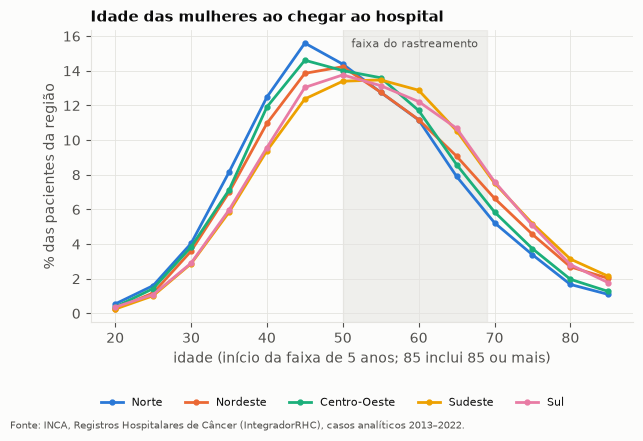

In [3]:
dist_idade = perfil.distribuicao_idade(rhc).reset_index().melt(id_vars="faixa5", var_name="regiao", value_name="pct")
fig, ax = g.linhas(dist_idade, "faixa5", "pct", "regiao", "Idade das mulheres ao chegar ao hospital",
                   "% das pacientes da região", ordem=c.REGIOES, rotulos_finais=False,
                   rotulo_x="idade (início da faixa de 5 anos; 85 inclui 85 ou mais)")
ax.set_xticks(range(20, 90, 10))
ax.axvspan(50, 69, color=g.GRADE, alpha=0.5, zorder=0)
ax.text(59.5, ax.get_ylim()[1] * 0.97, "faixa do rastreamento", ha="center", va="top", fontsize=8, color=g.TEXTO_2)
g.salvar(fig, "02_idade_regiao", FONTE_RHC)
plt.show()

A curva do Norte está deslocada para a esquerda: há proporcionalmente mais mulheres de 35 a 49 anos e menos acima de 60. As curvas do Sudeste e do Sul são praticamente iguais. A faixa cinza marca a idade do rastreamento.

## Raça/cor

Raça/cor é autodeclarada e segue as categorias do IBGE. O gráfico mostra a composição em cada região.

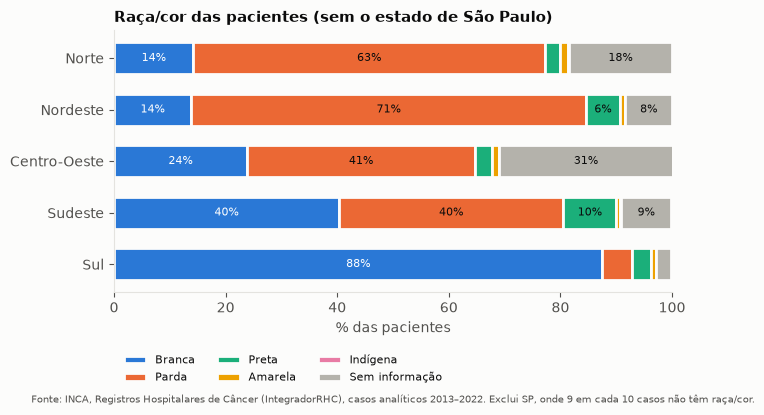

raca_cor,Branca,Parda,Preta,Amarela,Indígena,Sem informação
regiao_res,,,,,,
Norte,14.2,63.0,2.8,1.3,0.2,18.5
Nordeste,13.8,70.8,6.0,0.9,0.1,8.4
Centro-Oeste,23.8,40.9,3.1,1.1,0.1,31.1
Sudeste,19.0,18.9,4.5,0.3,0.1,57.2
Sul,87.5,5.4,3.4,0.8,0.0,2.8


In [4]:
ordem_raca = ["Branca", "Parda", "Preta", "Amarela", "Indígena", c.SEM_INFO]
raca = base.distribuicao(rhc, "raca_cor", ordem=ordem_raca)
raca_sem_sp = base.distribuicao(rhc[rhc.uf_res != "SP"], "raca_cor", ordem=ordem_raca)
base.salvar_tabela(raca, "02_raca_cor_regiao", index=True)
base.salvar_tabela(raca_sem_sp, "02_raca_cor_regiao_sem_sp", index=True)

fig, ax = g.empilhadas_100(raca_sem_sp, "Raça/cor das pacientes (sem o estado de São Paulo)")
g.salvar(fig, "02_raca_cor_regiao", FONTE_RHC + " Exclui SP, onde 9 em cada 10 casos não têm raça/cor.")
plt.show()
raca

A figura exclui São Paulo porque a base paulista quase não preenche raça/cor, e incluí-la faria o Sudeste parecer ter mais da metade das pacientes sem informação (a tabela logo acima, com São Paulo, mostra isso). Sem São Paulo, o retrato é coerente com a composição da população de cada região: maioria parda no Norte e no Nordeste, maioria branca no Sul, e Sudeste e Centro-Oeste divididos. O caderno 04 mostra que essa composição importa, porque mulheres pretas e pardas chegam com estádio mais avançado em todas as regiões.

Uma observação sobre ancestralidade. Nenhuma base pública brasileira de câncer registra ancestralidade genética. As informações mais próximas são a raça/cor autodeclarada, que é uma categoria social e não genética, e o estado de nascimento, discutido adiante. Uma análise de ancestralidade exigiria dados de estudos genômicos, que poderiam ser trazidos da literatura para a discussão.

## Escolaridade

Escolaridade é o principal indicador socioeconômico disponível no RHC. Para facilitar a comparação, as seis categorias originais foram agrupadas em três.

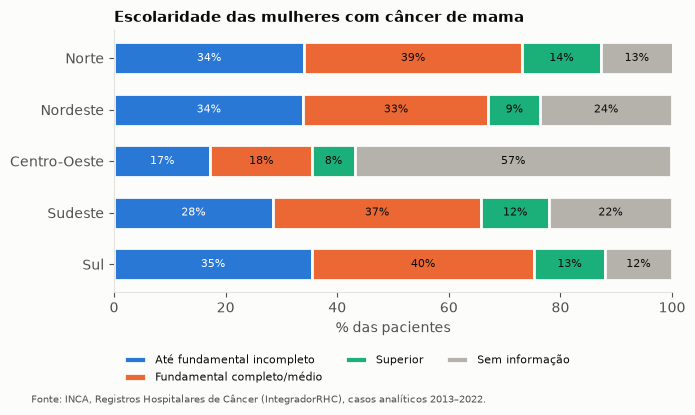

In [5]:
ordem_esc = c.ESCOLARIDADE_GRUPO_ORDEM + [c.SEM_INFO]
esc = base.distribuicao(rhc, "escolaridade_grupo", ordem=ordem_esc)
base.salvar_tabela(esc, "02_escolaridade_regiao", index=True)
fig, ax = g.empilhadas_100(esc, "Escolaridade das mulheres com câncer de mama")
g.salvar(fig, "02_escolaridade_regiao", FONTE_RHC)
plt.show()

Em todas as regiões, a maior parte das pacientes tem no máximo o ensino médio, e só uma em cada dez chegou ao ensino superior. No Centro-Oeste, mais da metade dos registros não tem escolaridade preenchida, então os percentuais dessa região devem ser lidos com cautela.

## Estado conjugal e histórico familiar

Estas duas variáveis aparecem aqui para completar o perfil. O histórico familiar de câncer é relevante porque mulheres com mãe ou irmã com câncer de mama têm risco maior e podem iniciar o rastreamento mais cedo.

In [6]:
conjugal = base.distribuicao(rhc, "estado_conjugal",
                             ordem=["Casada", "União consensual", "Solteira", "Viúva", "Separada", c.SEM_INFO])
historico = base.distribuicao(rhc[rhc.historico_familiar != c.SEM_INFO], "historico_familiar", ordem=["Sim", "Não"])
base.salvar_tabela(conjugal, "02_estado_conjugal_regiao", index=True)
display(conjugal)
display(historico.rename(columns=lambda x: f"histórico familiar: {x} (% entre informados)"))
print("Casos com histórico familiar informado:", f"{(rhc.historico_familiar != c.SEM_INFO).mean():.0%}")

estado_conjugal,Casada,União consensual,Solteira,Viúva,Separada,Sem informação
regiao_res,,,,,,
Norte,38.6,7.8,26.7,9.8,5.6,11.4
Nordeste,38.6,1.7,34.1,9.9,5.4,10.3
Centro-Oeste,28.9,2.2,20.4,7.0,5.8,35.7
Sudeste,20.6,1.1,10.7,6.3,4.5,56.8
Sul,39.5,3.1,15.5,10.7,8.0,23.2


historico_familiar,histórico familiar: Sim (% entre informados),histórico familiar: Não (% entre informados)
regiao_res,,
Norte,53.2,46.8
Nordeste,59.4,40.6
Centro-Oeste,59.8,40.2
Sudeste,59.4,40.6
Sul,64.4,35.6


Casos com histórico familiar informado: 51%


O estado conjugal está sem informação em mais da metade dos casos do Sudeste e em um terço dos do Centro-Oeste, então só as regiões Norte, Nordeste e Sul permitem uma leitura direta: nelas, cerca de 40% das pacientes são casadas e entre 15% e 34% são solteiras.

O histórico familiar exige atenção na interpretação. O campo do RHC registra se há qualquer caso de câncer, de qualquer tipo, em qualquer familiar, e não apenas câncer de mama em parentes próximos. Por isso o "sim" passa de 50% entre os casos informados, e esse número não deve ser lido como frequência de câncer de mama hereditário. Além disso, só metade dos casos tem o campo preenchido.

## Local de nascimento e migração

O RHC registra o estado de nascimento. Comparando com o estado de residência, é possível saber quantas pacientes migraram, o que ajuda a entender a composição da população atendida em cada região.

,% nascidas em outro estado
regiao_res,
Norte,32.7
Nordeste,8.0
Centro-Oeste,53.0
Sudeste,21.2
Sul,12.1


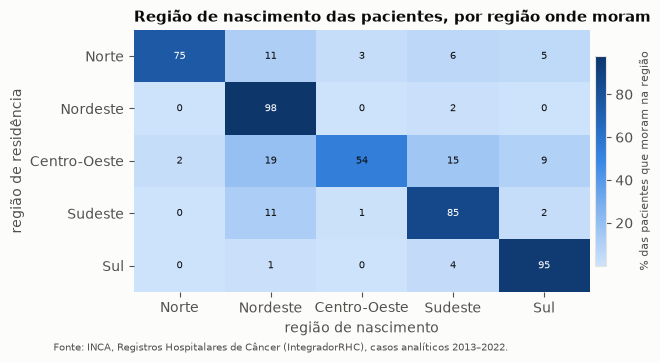

In [7]:
outra_uf = perfil.nascidas_em_outra_uf(rhc).rename("% nascidas em outro estado")
migr = perfil.migracao(rhc)
base.salvar_tabela(migr, "02_regiao_nascimento_x_residencia", index=True)
display(outra_uf.to_frame())
fig, ax = g.calor(migr, "Região de nascimento das pacientes, por região onde moram",
                  "% das pacientes que moram na região", figsize=(7, 3.4))
ax.set_xlabel("região de nascimento")
ax.set_ylabel("região de residência")
g.salvar(fig, "02_migracao", FONTE_RHC)
plt.show()

Cada linha soma 100%. No Nordeste e no Sul, quase todas as pacientes nasceram na própria região. No Centro-Oeste, só metade nasceu ali: 19% vieram do Nordeste e 15% do Sudeste, reflexo das migrações para Brasília e para a fronteira agrícola. No Norte, um quarto das pacientes nasceu em outra região. Esse dado ajuda a qualificar comparações regionais: as mulheres tratadas no Centro-Oeste carregam trajetórias de vida de várias partes do país.

## O que levar para o TCC

As pacientes do Norte são mais jovens, e lá uma parcela maior delas está abaixo da idade do rastreamento mamográfico. A grande maioria das pacientes do país tem escolaridade até o ensino médio. A composição por raça/cor acompanha a da população de cada região e, como mostra o caderno seguinte, está associada ao estádio ao diagnóstico. Ao citar raça/cor, é preciso dizer que São Paulo foi excluído por falta de preenchimento.